Disable just-in-time compilation with XLA.

[1, 1000]
no uniform points
Compiling model...
'compile' took 0.000396 s

Training model...

Step      Train loss              Test loss               Test metric   
0         [1.45e+05, 2.59e+01]    [1.52e+05, 2.55e+01]    [1.00e+00]    
1000      [9.30e+04, 1.05e+04]    [9.74e+04, 1.11e+04]    [1.02e+00]    
2000      [7.03e+02, 3.25e+03]    [7.61e+02, 3.73e+03]    [5.70e-01]    
3000      [1.37e+02, 5.22e+02]    [1.44e+02, 6.02e+02]    [3.62e-01]    
4000      [4.37e+02, 2.50e+02]    [4.41e+02, 2.67e+02]    [2.56e-01]    
5000      [2.03e+02, 1.66e+02]    [2.05e+02, 1.68e+02]    [1.69e-01]    
6000      [1.69e+01, 2.49e+01]    [1.91e+01, 2.98e+01]    [1.11e-01]    
7000      [5.30e+01, 4.06e+01]    [5.40e+01, 4.32e+01]    [7.30e-02]    
8000      [5.36e+01, 2.46e+01]    [5.47e+01, 2.59e+01]    [5.16e-02]    
9000      [2.29e+01, 2.49e+01]    [2.48e+01, 3.15e+01]    [1.04e-01]    
10000     [2.27e+01, 1.32e+01]    [2.51e+01, 1.55e+01]    [7

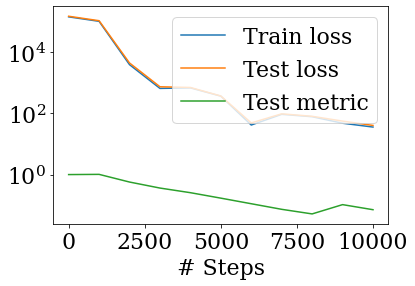

In [4]:
import os
os.environ['DDEBACKEND'] = 'tensorflow'
os.environ['CUDA_VISIBLE_DEVICES'] = '4'

import deepxde as dde 
dde.config.disable_xla_jit()

#class TensorGeometryXTime:
import numpy as np

class GeometryXGeometry:
    def __init__(self, geometry, k):
        self.geometry = geometry
        self.dim = geometry.dim ** k
        self.k = k
    
    def random_points(self, n, random="pseudo"):
        xx = []
        for i in range(self.k):
            xx.append(self.geometry.random_points(n, random=random))
        return np.hstack(xx)
    
    def uniform_points(self, n, boundary=False):
        print('no uniform points')
        return self.random_points(n)
    

"""Backend supported: tensorflow.compat.v1, tensorflow, pytorch"""
import deepxde as dde
import numpy as np

# General parameters
n = 1
k = 2

N_f = 5000
N_f_test = 5000

seed = 1234
dde.config.set_random_seed(seed)
weights = [1000 for i in range(k)]
weights[0] = 1
print(weights)

epochs = 10000

parameters = [1e-2, 2, 350, "sin"] 

# Define sine function
if dde.backend.backend_name == "pytorch":
    sin = dde.backend.pytorch.sin
else:
    from deepxde.backend import tf
    sin = tf.sin

learning_rate, num_dense_layers, num_dense_nodes, activation = parameters


def pde(x, y):
    #y_list = [y[:, i:i+1] for i in range(k)]
    V0, V1 = y[:, 0:1], y[:, 1:2]
    
    dV0_xx = dde.grad.hessian(y, x, component=0, i=0, j=0)
    dV0_yy = dde.grad.hessian(y, x, component=0, i=1, j=1)
    
    dV1_xx = dde.grad.hessian(y, x, component=1, i=2, j=2)
    dV1_yy = dde.grad.hessian(y, x, component=1, i=3, j=3)
    
    F = k0 ** 4 * sin(k0 * x[:, 0:1]) * sin(k0 * x[:, 1:2]) * sin(k0 * x[:, 2:3]) * sin(k0 * x[:, 3:4])
    
    L1 = - dV0_xx - dV0_yy - k0 ** 2 * V0 - F
    L2 = - dV1_xx - dV1_yy - k0 ** 2 * V1 - V0
    return [L1, L2]


def func(x):
    f1 = np.sin(k0 * x[:, 0:1]) * np.sin(k0 * x[:, 1:2])
    f2 = np.sin(k0 * x[:, 2:3]) * np.sin(k0 * x[:, 3:4])

    res_list = k * [None]
    
    for i in range(k-1):
        res_list[i] = 0 * f1
    res_list[-1] = f1 * f2
    return np.hstack(res_list)


def transform(x, y):
    res1 = x[:, 0:1] * (1 - x[:, 0:1]) * x[:, 1:2] * (1 - x[:, 1:2])
    res2 = x[:, 2:3] * (1 - x[:, 2:3]) * x[:, 3:4] * (1 - x[:, 3:4])

    y_list = [y[:, i:i+1] for i in range(k)]
    
    ys_list = k * [None]
    for i in range(k-1):
        ys_list[i] = y_list[i]
    ys_list[-1] = res1 * res2 * y_list[-1]
    ys = tf.concat(ys_list, axis=1)
    return ys

def l2_error(y_true, y_pred):
    pred = y_true - y_pred
    return np.linalg.norm(pred[:, k-1:k])/np.linalg.norm(y_true[:, k-1:k]) 


geom = dde.geometry.Rectangle([0, 0], [1, 1])
Geom = GeometryXGeometry(geom,2)    

k0 = 2 * np.pi * n
wave_len = 1 / n

data = dde.data.PDE(
    Geom,
    pde,
    train_distribution = 'pseudo',
    num_domain=N_f,
    solution=func,
    bcs = [],
    num_test=N_f_test,
)

net = dde.nn.FNN(
    [2 * k] + [num_dense_nodes] * num_dense_layers + [k], activation, "Glorot uniform"
)

net.apply_output_transform(transform)

model = dde.Model(data, net)

model.compile("adam", lr=learning_rate, metrics=[l2_error], loss_weights=weights)
#model.compile("adam", lr=learning_rate, metrics=[l2_error], loss_weights=weights, decay = ("inverse time", 10000, 0.5))

losshistory, train_state = model.train(epochs=epochs)
dde.saveplot(losshistory, train_state, issave=True, isplot=True)
    

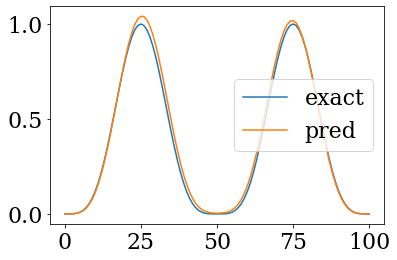

In [5]:
from matplotlib import pyplot as plt
x = np.array([np.arange(101)/100]).T
x_list = [x.T for i in range(2 * k)]
xx = np.concatenate(x_list).T
sol = func(xx)[:, k-1:k]
pred = model.predict(xx)[:, k-1:k]

plt.plot(sol.ravel(), label='exact')
plt.plot(pred.ravel(), label='pred')
plt.legend()

Relative error =  0.06089826428886758


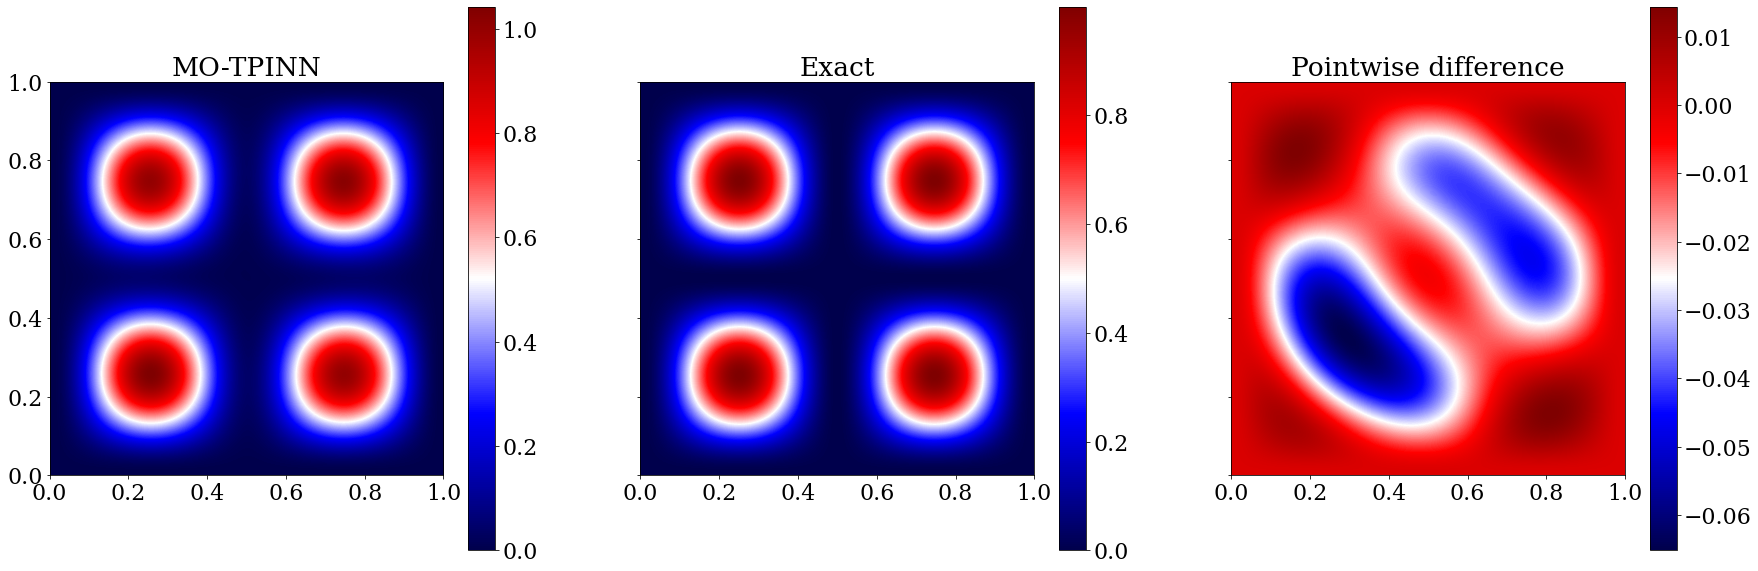

In [16]:
from matplotlib import pyplot as plt
'''            Evaluate field over a specified grid of points              '''
# Square grid with 10 points per wavelength in each direction
Nx = 100
Ny = Nx

# Grid points
xmin, xmax, ymin, ymax = [0,1,0,1]
plot_grid = np.mgrid[xmin:xmax:Nx * 1j, ymin:ymax:Ny * 1j]
points = np.vstack((plot_grid[0].ravel(),
                    plot_grid[1].ravel(),
                    np.zeros(plot_grid[0].size)))

points_2d = points[:2, :]
points_4d = np.hstack([points_2d.T, points_2d.T])

u_exact = func(points_4d)[:, 1:2]
u_sca = model.predict(points_4d)[:, 1:2]
u_exact = u_exact.reshape((Nx, Ny))
u_sca = u_sca.reshape((Nx, Ny))

'''                  Compare against analytical solution                    '''
# Uncomment to perform comparison, takes a few seconds to run




diff = u_exact-u_sca
error = np.linalg.norm(diff)/np.linalg.norm(u_exact)
print('Relative error = ', error)

'''                     Plot field and save figure                          '''
plt.rc('font', family='serif', size=22)



fig, (ax1, ax2, ax3) = plt.subplots(1, 3, sharey=True, figsize = (30,10))


pcm = ax1.imshow(np.fliplr(u_sca).T,
           extent=[0,1,0,1],
           cmap=plt.cm.get_cmap('seismic'), interpolation='spline16', label='V-TPINN')

#ax1.axis('off')
fig.colorbar(pcm, ax = ax1)

pcm = ax2.imshow(np.fliplr(u_exact).T,
           extent=[0,1,0,1],
           cmap=plt.cm.get_cmap('seismic'), interpolation='spline16', label = 'Exact')


fig.colorbar(pcm, ax = ax2)

pcm = ax3.imshow(np.fliplr(diff).T,
           extent=[0,1,0,1],
           cmap=plt.cm.get_cmap('seismic'), interpolation='spline16', label = 'Exact')

ax3.set_title('Pointwise difference')


#ax2.scatter(data.test_x[:, 0:1], data.test_x[:, 1:2])
#ax1.scatter(data.train_x[:, 0:1], data.train_x[:, 1:2])
#ax1.axis('off')
ax1.set_title('MO-TPINN')
ax2.set_title('Exact')

fig.colorbar(pcm, ax = ax3)

plt.savefig('solhelm.pdf')